# MedStruct: rhetorical role classification of biomedical abstracts (corrected version)

**Before you start**
1. Runtime → Change runtime type → **T4 GPU**. The notebook refuses to run a full experiment on CPU.
2. Keep `SMOKE = True` for the first run: it uses a few hundred abstracts so you can check every cell in minutes. Then set `SMOKE = False`.
3. Rough cost: SMOKE finishes in minutes; a real run needs hours on a T4 (several epochs over 180k sentences per model and seed). Look at the `train_s` column after the smoke run and reduce `SEEDS`, `SENT_MODELS` or the ablation if you are short of time.
4. Everything is saved to Google Drive (`medstruct/`), and finished runs are skipped when you rerun a cell, so a Colab disconnect does not lose work.

**What changed compared with the first version**
- Fixed label order, seeds `[1, 2, 3]` everywhere, GPU check.
- Position bins no longer drop the first sentence of each abstract (`rel_pos = (idx + 0.5) / n`).
- Position-only baseline uses a tree model on relative position; TF-IDF baseline also reports test.
- BiLSTM: padding is masked (packed sequences), real training with early stopping on dev macro-F1.
- Sentence transformers: warmup scheduler, best epoch chosen by dev macro-F1, test evaluation, predictions saved to disk.
- Hierarchical model: encodes only real sentences, handles padding with packed sequences, supports a context window `k` for the ablation, and keeps predictions aligned with the dataframe (the old collate function sorted the batch, which would have misaligned predictions).
- Out-of-domain: digits are normalized to `@` to match the dataset, and scoring uses only the labels shared with the target set.
- Bootstrap resamples **abstracts**, full size, two-sided p-value plus a 95% confidence interval.
- Tools for the annotation sheet and Cohen's kappa.

In [2]:
# !pip -q install transformers datasets      # uncomment on a fresh Colab runtime
import os, re, json, time, copy, random, gc
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import f1_score, precision_recall_fscore_support, confusion_matrix, cohen_kappa_score

# ------------------------------- configuration -------------------------------
SMOKE = True                      # True = tiny fast check of the code. False = real experiments.
SEEDS = [1, 2, 3, 4, 5]           # review A: >= 3 seeds (ideally 5) so the improvement survives re-initialisation
LABELS = ['BACKGROUND', 'OBJECTIVE', 'METHODS', 'RESULTS', 'CONCLUSIONS']   # fixed order, used everywhere
L2I = {l: i for i, l in enumerate(LABELS)}
NC = len(LABELS)

if SMOKE:
    CFG = dict(seeds=[1], n_train=200, n_dev=60, n_test=60, bilstm_epochs=1, tf_epochs=1, hier_epochs=1)
else:
    CFG = dict(seeds=SEEDS, n_train=None, n_dev=None, n_test=None, bilstm_epochs=10, tf_epochs=3, hier_epochs=3)

MODEL_NAMES = {
    'BERT': 'bert-base-uncased',
    'BioBERT': 'dmis-lab/biobert-v1.1',
    'PubMedBERT': 'microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext',
}
SENT_MODELS = ['BERT', 'BioBERT']          # add 'PubMedBERT' if you have time
MAX_LEN, SENT_BS, HIER_BS = 96, 32, 4       # HIER_BS = abstracts per batch (about 12 sentences each)

# ------------------------------- storage -------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/medstruct'
except ImportError:
    BASE = './medstruct'
DATA_DIR, RES_DIR, PRED_DIR, CKPT_DIR = (f'{BASE}/data', f'{BASE}/results', f'{BASE}/results/preds', f'{BASE}/checkpoints')
for d in (DATA_DIR, RES_DIR, PRED_DIR, CKPT_DIR):
    os.makedirs(d, exist_ok=True)
SAVE_CKPT = not SMOKE                       # checkpoints are ~440 MB each, only save in real runs

# ------------------------------- device & seeds ------------------------------
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'
print('device:', DEVICE, '| torch', torch.__version__)
if DEVICE.type == 'cpu' and not SMOKE:
    raise RuntimeError('No GPU found. Switch the Colab runtime to a T4 GPU, or set SMOKE = True.')

def set_seed(seed):
    random.seed(seed); os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
set_seed(1)

device: cpu | torch 2.15.0+cpu


# Data: parsing and sanity checks

In [3]:
# [pure]
import urllib.request
URL = 'https://raw.githubusercontent.com/Franck-Dernoncourt/pubmed-rct/master/PubMed_20k_RCT_numbers_replaced_with_at_sign/'
for f in ['train.txt', 'dev.txt', 'test.txt']:
    dest = os.path.join(DATA_DIR, f)
    if not os.path.exists(dest):
        print('downloading', f); urllib.request.urlretrieve(URL + f, dest)

def parse_pubmed_rct(path):
    # Each abstract: a '###<id>' line, then 'LABEL<TAB>sentence' lines, then a blank line.
    rows, aid, sents = [], None, []
    def flush():
        n = len(sents)
        for i, (lab, txt) in enumerate(sents):
            rows.append((aid, i, n, lab, txt))
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.rstrip('\n')
            if line.startswith('###'):
                if sents: flush()
                aid, sents = line[3:].strip(), []
            elif line.strip() == '':
                if sents: flush(); sents = []
            else:
                p = line.split('\t', 1)
                if len(p) == 2: sents.append((p[0], p[1]))
    if sents: flush()
    df = pd.DataFrame(rows, columns=['abstract_id', 'sent_idx', 'n_sents', 'label', 'text'])
    df['rel_pos'] = (df['sent_idx'] + 0.5) / df['n_sents']     # strictly inside (0, 1): no sentence is lost when binning
    return df

def assert_contiguous(df):
    # Every model assumes: rows of one abstract are adjacent and in sentence order. Predictions are aligned by row order.
    ids = df['abstract_id'].values
    changes = (ids[1:] != ids[:-1]).sum() + 1
    assert changes == df['abstract_id'].nunique(), 'rows of the same abstract are not contiguous'
    assert (df.groupby('abstract_id', sort=False)['sent_idx'].apply(lambda s: (np.diff(s.values) == 1).all())).all()

train_df = parse_pubmed_rct(f'{DATA_DIR}/train.txt')
val_df   = parse_pubmed_rct(f'{DATA_DIR}/dev.txt')
test_df  = parse_pubmed_rct(f'{DATA_DIR}/test.txt')
for n, d in [('train', train_df), ('dev', val_df), ('test', test_df)]:
    assert set(d['label']) == set(LABELS), set(d['label'])
    assert_contiguous(d)
    print(f'{n}: {len(d):,} sentences, {d.abstract_id.nunique():,} abstracts')   # expected 180,040 / 30,212 / 30,135 sentences

def normalize_numbers(text):
    # The dataset replaces numbers with '@'. Apply the same rule to any external text (CSAbstruct, your gold set, the demo).
    return re.sub(r'\d+', '@', text)

def first_n_abstracts(df, n):
    if n is None: return df
    keep = df['abstract_id'].drop_duplicates().iloc[:n]
    return df[df['abstract_id'].isin(set(keep))].reset_index(drop=True)

# data used by the neural experiments (tiny in SMOKE mode, full otherwise)
RUN_TRAIN = first_n_abstracts(train_df, CFG['n_train'])
RUN_DEV   = first_n_abstracts(val_df,   CFG['n_dev'])
RUN_TEST  = first_n_abstracts(test_df,  CFG['n_test'])
print('neural experiments use:', len(RUN_TRAIN), len(RUN_DEV), len(RUN_TEST), 'sentences')

train: 180,040 sentences, 15,000 abstracts
dev: 30,212 sentences, 2,500 abstracts
test: 30,135 sentences, 2,500 abstracts
neural experiments use: 2429 755 723 sentences


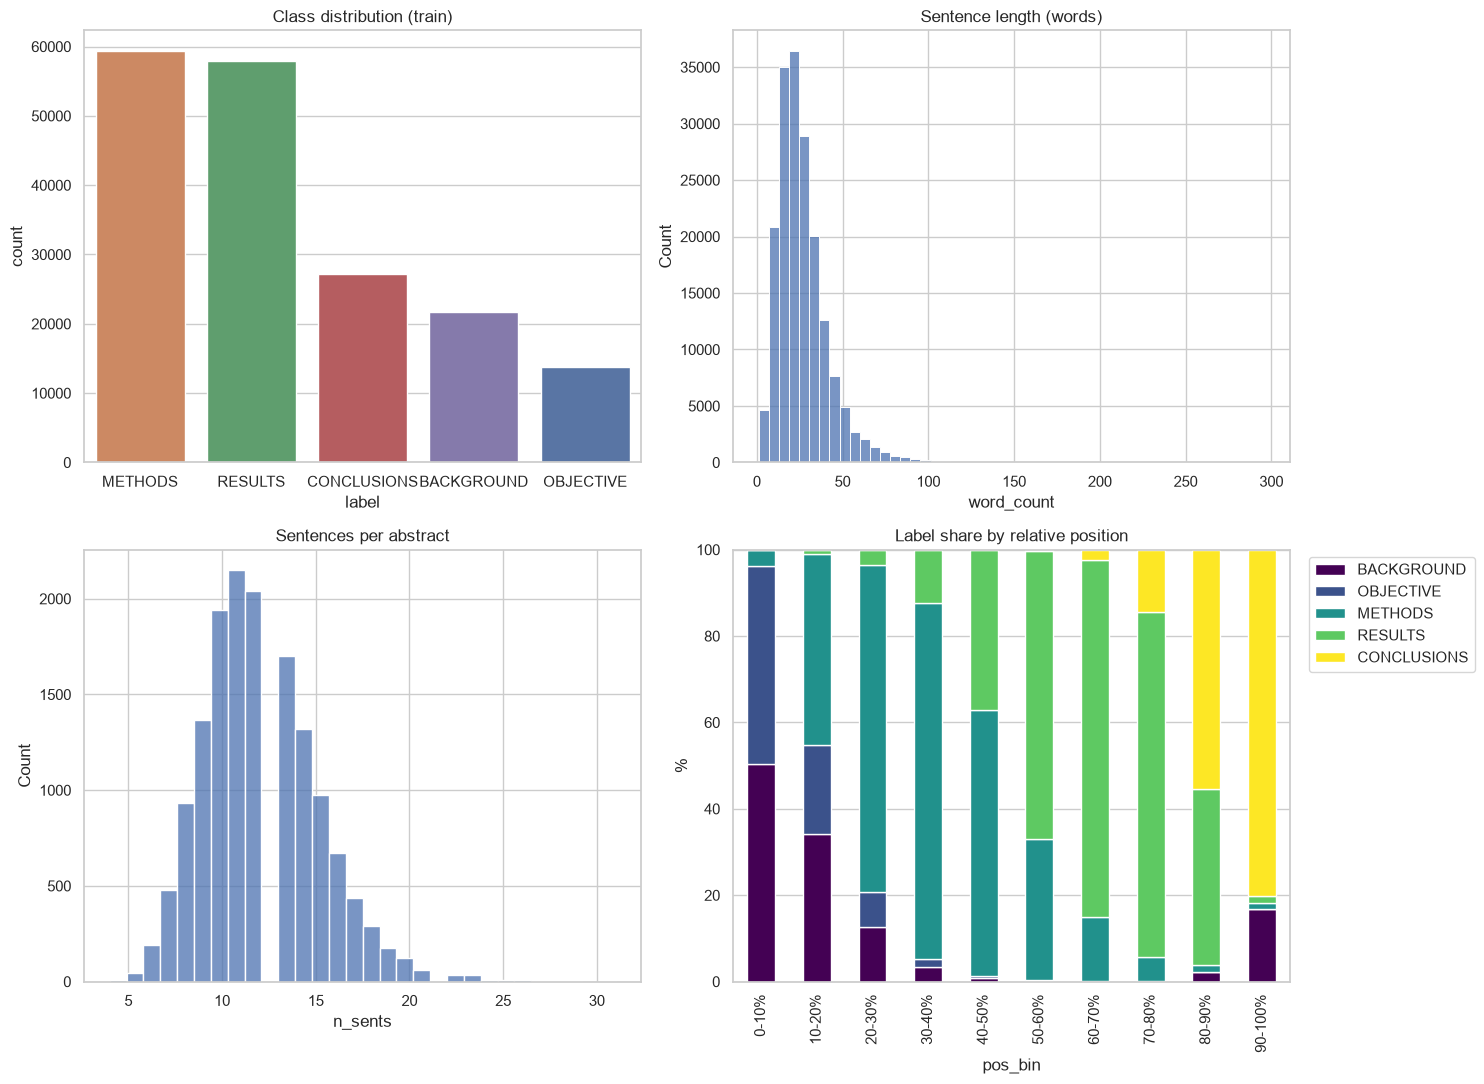

label
METHODS        0.330
RESULTS        0.322
CONCLUSIONS    0.151
BACKGROUND     0.121
OBJECTIVE      0.077
Name: proportion, dtype: float64


In [4]:
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(2, 2, figsize=(15, 11))
order = train_df['label'].value_counts().index
sns.countplot(data=train_df, x='label', order=order, hue='label', legend=False, ax=ax[0, 0]); ax[0, 0].set_title('Class distribution (train)')
train_df['word_count'] = train_df['text'].str.split().str.len()
sns.histplot(train_df['word_count'], bins=50, ax=ax[0, 1]); ax[0, 1].set_title('Sentence length (words)')
sns.histplot(train_df.drop_duplicates('abstract_id')['n_sents'], bins=30, ax=ax[1, 0]); ax[1, 0].set_title('Sentences per abstract')
bins = np.linspace(0, 1, 11)
train_df['pos_bin'] = pd.cut(train_df['rel_pos'], bins=bins, labels=[f'{int(b*100)}-{int(b*100)+10}%' for b in bins[:-1]])
pct = pd.crosstab(train_df['pos_bin'], train_df['label'], normalize='index')[LABELS] * 100
assert train_df['pos_bin'].notna().all()          # the first sentence of every abstract is now included
pct.plot(kind='bar', stacked=True, ax=ax[1, 1], colormap='viridis'); ax[1, 1].set_title('Label share by relative position')
ax[1, 1].set_ylabel('%'); ax[1, 1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout(); plt.show()
print(train_df['label'].value_counts(normalize=True).round(3))

# Evaluation utilities, result log, predictions on disk

In [5]:
# [pure]
def macro_f1(y_true, y_pred, labels=LABELS):
    return f1_score(y_true, y_pred, labels=labels, average='macro', zero_division=0)

def evaluate_model(y_true, y_pred, name='Model', labels=LABELS, plot=True):
    mf1 = macro_f1(y_true, y_pred, labels)
    p, r, f, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    table = pd.DataFrame({'Precision': p, 'Recall': r, 'F1': f, 'Support': s}, index=labels).round(4)
    print(f'=== {name}: macro-F1 = {mf1:.4f}'); print(table.to_string())
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    if plot:
        plt.figure(figsize=(6.5, 5))
        sns.heatmap(cm / cm.sum(1, keepdims=True).clip(min=1), annot=cm, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
        plt.title(f'{name} (colour = row-normalised, numbers = counts)'); plt.ylabel('True'); plt.xlabel('Predicted'); plt.tight_layout(); plt.show()
    return dict(macro_f1=mf1, table=table, cm=cm)

def idx_to_labels(idx): return np.array(LABELS)[np.asarray(idx)]

def save_predictions(run_id, split, df, pred_labels):
    out = df[['abstract_id', 'sent_idx', 'n_sents', 'label']].copy(); out['pred'] = list(pred_labels)
    out.to_csv(f'{PRED_DIR}/{run_id}__{split}.csv', index=False)

def load_predictions(run_id, split):
    return pd.read_csv(f'{PRED_DIR}/{run_id}__{split}.csv', dtype={'abstract_id': str})

# result log: one row per run, saved to Drive, so finished runs are skipped when a cell is rerun
RES_PATH = f'{RES_DIR}/results.csv'
RESULTS = pd.read_csv(RES_PATH).to_dict('records') if os.path.exists(RES_PATH) else []
def is_done(run_id): return any(r['run_id'] == run_id for r in RESULTS)
def log_record(rec):
    RESULTS[:] = [r for r in RESULTS if r['run_id'] != rec['run_id']] + [rec]
    pd.DataFrame(RESULTS).to_csv(RES_PATH, index=False)
print(len(RESULTS), 'runs already logged')

17 runs already logged


# Baselines (position-only and TF-IDF + logistic regression)

=== Position-only (dev): macro-F1 = 0.6275
             Precision  Recall      F1  Support
BACKGROUND      0.4743  0.4016  0.4349     3449
OBJECTIVE       0.5616  0.3548  0.4349     2376
METHODS         0.7167  0.7612  0.7383     9964
RESULTS         0.7402  0.7865  0.7626     9841
CONCLUSIONS     0.7531  0.7809  0.7667     4582


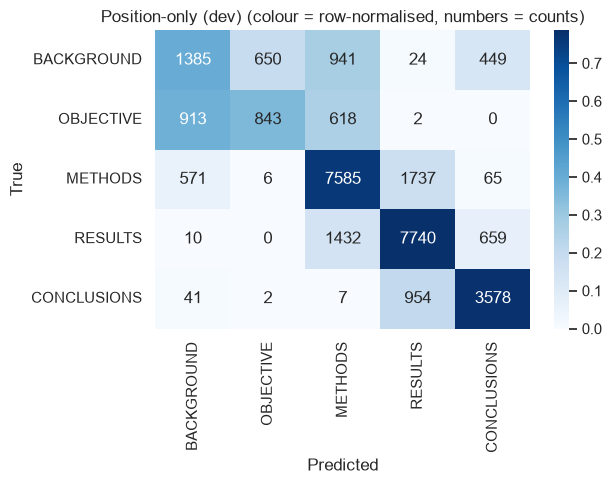

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer

# --- position only: relative position + position index + length, a tree model can use them non-linearly ---
feats = ['sent_idx', 'n_sents', 'rel_pos']
t0 = time.time()
pos_model = HistGradientBoostingClassifier(max_iter=200, random_state=1).fit(train_df[feats], train_df['label'])
pos_time = time.time() - t0
p_dev, p_test = pos_model.predict(val_df[feats]), pos_model.predict(test_df[feats])
r = evaluate_model(val_df['label'], p_dev, 'Position-only (dev)')
save_predictions('position', 'dev', val_df, p_dev); save_predictions('position', 'test', test_df, p_test)
log_record(dict(run_id='position', model='Position-only', seed=1, frac=1.0, window='', dev_f1=r['macro_f1'],
                test_f1=macro_f1(test_df['label'], p_test), train_s=pos_time))

=== TF-IDF + LR (dev): macro-F1 = 0.7671
             Precision  Recall      F1  Support
BACKGROUND      0.6571  0.6796  0.6682     3449
OBJECTIVE       0.6893  0.5518  0.6129     2376
METHODS         0.8892  0.9240  0.9063     9964
RESULTS         0.8832  0.8879  0.8855     9841
CONCLUSIONS     0.7697  0.7551  0.7624     4582


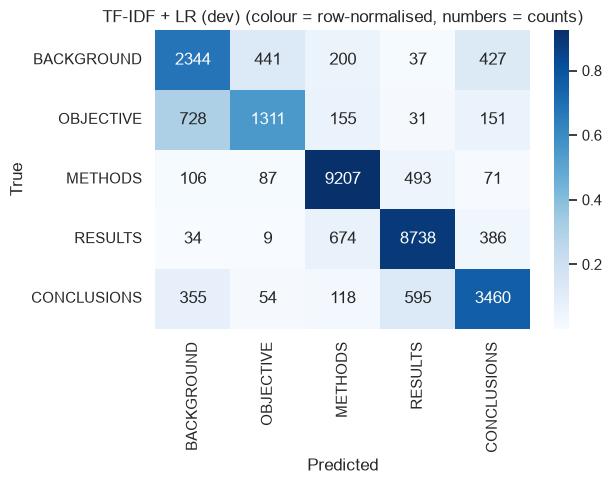

test macro-F1: 0.7599 (reported for the final table, not used for any choice)


In [7]:
t0 = time.time()
vec = TfidfVectorizer(ngram_range=(1, 2), max_features=100000, sublinear_tf=True)
Xtr, Xdv, Xte = vec.fit_transform(train_df['text']), vec.transform(val_df['text']), vec.transform(test_df['text'])
tfidf = LogisticRegression(max_iter=1000, C=3.0, random_state=1).fit(Xtr, train_df['label'])
tf_time = time.time() - t0
p_dev, p_test = tfidf.predict(Xdv), tfidf.predict(Xte)
r = evaluate_model(val_df['label'], p_dev, 'TF-IDF + LR (dev)')
save_predictions('tfidf', 'dev', val_df, p_dev); save_predictions('tfidf', 'test', test_df, p_test)
log_record(dict(run_id='tfidf', model='TF-IDF + LR', seed=1, frac=1.0, window='', dev_f1=r['macro_f1'],
                test_f1=macro_f1(test_df['label'], p_test), train_s=tf_time))
print('test macro-F1:', round(macro_f1(test_df['label'], p_test), 4), '(reported for the final table, not used for any choice)')

# Shared helpers for all neural models
`finalize` evaluates one trained model on dev, test and any extra sets (out-of-domain, gold set), saves predictions, and logs one row.
For extra sets, the true labels may contain `OTHER` (CSAbstruct); those sentences stay in the abstract as context but are not scored,
and macro-F1 is computed only over the labels present in that set.

In [8]:
def score_extra(df, pred_labels):
    pred_labels = np.asarray(pred_labels)
    shared = [l for l in LABELS if l in set(df['label'])]
    mask = df['label'].isin(shared).values
    return macro_f1(df['label'].values[mask], pred_labels[mask], labels=shared)

def finalize(run_id, meta, predict, dev_df, test_df, extra_eval=None):
    # predict(df) -> array of label indices, in the row order of df
    t0 = time.time(); p_test = predict(test_df)
    latency = (time.time() - t0) / test_df['abstract_id'].nunique() * 1000
    p_dev = predict(dev_df)
    rec = dict(run_id=run_id, **meta)
    rec['dev_f1'] = macro_f1(dev_df['label'], idx_to_labels(p_dev))
    rec['test_f1'] = macro_f1(test_df['label'], idx_to_labels(p_test))
    rec['latency_ms_per_abstract'] = latency
    save_predictions(run_id, 'dev', dev_df, idx_to_labels(p_dev)); save_predictions(run_id, 'test', test_df, idx_to_labels(p_test))
    for name, edf in (extra_eval or {}).items():
        pe = idx_to_labels(predict(edf)); save_predictions(run_id, name, edf, pe); rec[f'{name}_f1'] = score_extra(edf, pe)
    log_record(rec)
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items()})
    return rec

def n_params(model): return sum(p.numel() for p in model.parameters()) / 1e6

# Out-of-domain and unstructured test sets (RQ2)
Both sets are put in the same dataframe format as PubMed, with digits normalised to `@`, then collected in `EXTRA_EVAL`.
Every model evaluates itself on all sets in `EXTRA_EVAL` when it finishes training. The gold set will not exist until your second annotation pass,
so afterwards call `eval_saved([...run ids...])` (defined after the hierarchical section): it reloads saved checkpoints and adds the gold-set scores. This needs `SMOKE = False` (checkpoints are only saved in real runs).

**CSAbstruct**: its label scheme is background / objective / method / result / other. There is **no conclusion class** — conclusion-like sentences fall under `other` in CSAbstruct. The transfer score therefore reports **only the four compatible classes** (BACKGROUND, OBJECTIVE, METHODS, RESULTS): gold `other` sentences are kept as encoder context but excluded from scoring, and a predicted CONCLUSIONS on a scored sentence counts as an error. The missing-conclusion mismatch is inherent to the dataset, not a modelling choice; mention it when comparing with published CSAbstruct numbers.

In [9]:
# [pure]
CSA_MAP = {'background': 'BACKGROUND', 'objective': 'OBJECTIVE', 'method': 'METHODS', 'methods': 'METHODS', 'result': 'RESULTS', 'results': 'RESULTS', 'other': 'OTHER'}

def records_to_df(records, prefix):
    rows = []
    for i, rec in enumerate(records):
        sents, labs = rec['sentences'], rec['labels']
        for j, (s, l) in enumerate(zip(sents, labs)):
            rows.append((f"{prefix}{rec.get('abstract_id', i)}", j, len(sents), CSA_MAP[str(l).lower()], normalize_numbers(s)))
    df = pd.DataFrame(rows, columns=['abstract_id', 'sent_idx', 'n_sents', 'label', 'text'])
    df['rel_pos'] = (df['sent_idx'] + 0.5) / df['n_sents']
    return df

def load_csabstruct(split='test', local_jsonl=None):
    # Option A: local jsonl (from github.com/allenai/sequential_sentence_classification, folder data/CSAbstrcut).
    # Option B: Hugging Face hub dataset 'allenai/csabstruct'. Check the printed record keys and adjust if the format differs.
    if local_jsonl:
        recs = [json.loads(l) for l in open(local_jsonl, encoding='utf-8')]
    else:
        from datasets import load_dataset
        ds = load_dataset('allenai/csabstruct', split=split)
        feat = ds.features.get('labels'); names = getattr(getattr(feat, 'feature', None), 'names', None)
        recs = [dict(r, labels=[names[x] if names else x for x in r['labels']]) for r in ds]
    print('record keys:', list(recs[0].keys()), '| first labels:', recs[0]['labels'][:5])
    df = records_to_df(recs, 'csa')
    assert_contiguous(df)
    return df

def load_gold_csv(path):
    # your annotated unstructured abstracts: columns abstract_id, sent_idx, label, text
    g = pd.read_csv(path, dtype={'abstract_id': str})
    g['label'] = g['label'].str.upper().str.strip(); assert set(g['label']) <= set(LABELS), set(g['label']) - set(LABELS)
    g['text'] = g['text'].map(normalize_numbers); g['n_sents'] = g.groupby('abstract_id')['sent_idx'].transform('count')
    g['rel_pos'] = (g['sent_idx'] + 0.5) / g['n_sents']; assert_contiguous(g)
    return g

EXTRA_EVAL = {}
try:
    EXTRA_EVAL['csabstruct'] = first_n_abstracts(load_csabstruct('test'), 60 if SMOKE else None)
    print('CSAbstruct:', EXTRA_EVAL['csabstruct'].abstract_id.nunique(), 'abstracts', EXTRA_EVAL['csabstruct']['label'].value_counts().to_dict())
except Exception as e:
    print('CSAbstruct not loaded:', repr(e)[:200])
gold_path = f'{DATA_DIR}/gold_pass_final.csv'
if os.path.exists(gold_path):
    EXTRA_EVAL['gold'] = load_gold_csv(gold_path); print('gold set:', EXTRA_EVAL['gold'].abstract_id.nunique(), 'abstracts')

def baselines_on_extra():
    # the two classical baselines are cheap, so evaluate them on the extra sets right away
    fns = {'tfidf': lambda d: tfidf.predict(vec.transform(d['text'])), 'position': lambda d: pos_model.predict(d[feats])}
    for rid, fn in fns.items():
        rec = next(r for r in RESULTS if r['run_id'] == rid).copy()
        for name, edf in EXTRA_EVAL.items():
            pe = fn(edf); save_predictions(rid, name, edf, pe); rec[f'{name}_f1'] = score_extra(edf, pe)
        log_record(rec)
if EXTRA_EVAL: baselines_on_extra()

README.md:   0%|          | 0.00/2.90k [00:00<?, ?B/s]

d:\Dhia\project\nlp\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\pc\.cache\huggingface\hub\datasets--allenai--csabstruct. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


csabstruct.py:   0%|          | 0.00/3.98k [00:00<?, ?B/s]

CSAbstruct not loaded: RuntimeError('Dataset scripts are no longer supported, but found csabstruct.py')


# Deep-learning baseline: BiLSTM (masked, trained properly)

In [10]:
from collections import Counter

def build_vocab(texts, min_count=2):
    cnt = Counter(t for s in texts for t in s.lower().split())
    return {w: i for i, w in enumerate(['<PAD>', '<UNK>'] + [w for w, c in cnt.items() if c >= min_count])}

def encode_texts(texts, w2i, max_len=64):
    X = torch.zeros(len(texts), max_len, dtype=torch.long)
    for i, s in enumerate(texts):
        ids = [w2i.get(t, 1) for t in s.lower().split()[:max_len]]
        X[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)
    return X

class BiLSTMClassifier(nn.Module):
    def __init__(self, V, E=128, H=128, C=NC, drop=0.3):
        super().__init__()
        self.emb = nn.Embedding(V, E, padding_idx=0)
        self.lstm = nn.LSTM(E, H, batch_first=True, bidirectional=True)
        self.drop, self.fc = nn.Dropout(drop), nn.Linear(2 * H, C)
    def forward(self, x):
        mask = x != 0
        lens = mask.sum(1).clamp(min=1).cpu()
        packed = pack_padded_sequence(self.drop(self.emb(x)), lens, batch_first=True, enforce_sorted=False)
        out, _ = self.lstm(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        m = mask.unsqueeze(-1).float()
        pooled = (out * m).sum(1) / m.sum(1).clamp(min=1)       # mean over real tokens only
        return self.fc(self.drop(pooled))

@torch.no_grad()
def predict_bilstm(model, X):
    model.eval(); out = []
    for i in range(0, len(X), 512): out.append(model(X[i:i + 512].to(DEVICE)).argmax(1).cpu())
    return torch.cat(out).numpy()

def train_bilstm(seed, train, dev, test, epochs, extra_eval=None, patience=2, bs=128, lr=2e-3):
    run_id = f'bilstm_s{seed}'
    if is_done(run_id): print('skip', run_id); return
    set_seed(seed)
    w2i = build_vocab(train['text'])
    Xtr, ytr = encode_texts(train['text'].tolist(), w2i), torch.tensor(train['label'].map(L2I).values)
    Xdv = encode_texts(dev['text'].tolist(), w2i)
    model = BiLSTMClassifier(len(w2i)).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    loader = DataLoader(TensorDataset(Xtr, ytr), batch_size=bs, shuffle=True)

    best, best_state, bad, t0 = -1, None, 0, time.time()
    for ep in range(epochs):
        model.train(); tot = 0
        for xb, yb in loader:
            opt.zero_grad(); loss = F.cross_entropy(model(xb.to(DEVICE)), yb.to(DEVICE)); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tot += loss.item()
        f1 = macro_f1(dev['label'], idx_to_labels(predict_bilstm(model, Xdv)))
        print(f'epoch {ep+1}/{epochs} loss {tot/len(loader):.4f} dev macro-F1 {f1:.4f}')
        if f1 > best: best, best_state, bad = f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break
    train_s = time.time() - t0
    model.load_state_dict(best_state)
    torch.save({'state': best_state, 'w2i': w2i}, f'{CKPT_DIR}/{run_id}.pt')      # small, always saved
    predict = lambda df: predict_bilstm(model, encode_texts(df['text'].tolist(), w2i))
    return finalize(run_id, dict(model='BiLSTM', kind='bilstm', key='BiLSTM', seed=seed, frac=1.0, window='', train_s=train_s, params_M=n_params(model)), predict, dev, test, extra_eval)

for s in CFG['seeds']:
    train_bilstm(s, RUN_TRAIN, RUN_DEV, RUN_TEST, CFG['bilstm_epochs'], EXTRA_EVAL)

skip bilstm_s1


# Sentence-level transformers (BERT, BioBERT, optional PubMedBERT)
Each sentence is classified independently from its `[CLS]` vector. The best epoch is chosen by **dev macro-F1**, then dev, test and extra sets are evaluated and predictions are saved.

In [11]:
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup

def make_encoder(name): return AutoModel.from_pretrained(name)
def make_tokenizer(name):
    try:
        return AutoTokenizer.from_pretrained(name)
    except ValueError:      # fast backend could not be built (stale/incomplete HF cache or missing dep)
        try:
            return AutoTokenizer.from_pretrained(name, force_download=True)      # recover from a bad cache entry
        except Exception:
            return AutoTokenizer.from_pretrained(name, use_fast=False)      # last resort: slow tokenizer

def tokenize(tok, texts, max_len=MAX_LEN):
    enc = tok(list(texts), padding='max_length', truncation=True, max_length=max_len, return_tensors='pt')
    return enc['input_ids'], enc['attention_mask']

class SentClassifier(nn.Module):
    def __init__(self, encoder, C=NC, drop=0.1):
        super().__init__()
        self.enc, self.drop = encoder, nn.Dropout(drop)
        self.out = nn.Linear(encoder.config.hidden_size, C)
    def forward(self, ids, mask):
        L = int(mask.sum(1).max()); ids, mask = ids[:, :L], mask[:, :L]        # trim padding of the batch
        return self.out(self.drop(self.enc(input_ids=ids, attention_mask=mask).last_hidden_state[:, 0]))

@torch.no_grad()
def predict_sent_tok(model, I, M):
    model.eval(); out = []
    for i in range(0, len(I), 256):
        with torch.amp.autocast('cuda', enabled=AMP): out.append(model(I[i:i + 256].to(DEVICE), M[i:i + 256].to(DEVICE)).argmax(1).cpu())
    return torch.cat(out).numpy()

def train_sentence_model(key, seed, train, dev, test, epochs, extra_eval=None, tag='sent', frac=1.0, bs=SENT_BS, lr=2e-5):
    run_id = f'{key}_{tag}_f{frac}_s{seed}'
    if is_done(run_id): print('skip', run_id); return
    set_seed(seed); name = MODEL_NAMES[key]; print(f'=== {run_id} ({name}) ===')
    tok = make_tokenizer(name)
    ids, mask = tokenize(tok, train['text']); y = torch.tensor(train['label'].map(L2I).values)
    dids, dmask = tokenize(tok, dev['text'])
    model = SentClassifier(make_encoder(name)).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
    loader = DataLoader(TensorDataset(ids, mask, y), batch_size=bs, shuffle=True)
    total = epochs * len(loader); sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)

    best, best_state, t0 = -1, None, time.time()
    for ep in range(epochs):
        model.train(); tot = 0
        for ib, mb, yb in loader:
            opt.zero_grad()
            with torch.amp.autocast('cuda', enabled=AMP): loss = F.cross_entropy(model(ib.to(DEVICE), mb.to(DEVICE)), yb.to(DEVICE))
            scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); tot += loss.item()
        f1 = macro_f1(dev['label'], idx_to_labels(predict_sent_tok(model, dids, dmask)))
        print(f'epoch {ep+1}/{epochs} loss {tot/len(loader):.4f} dev macro-F1 {f1:.4f}')
        if f1 > best: best, best_state = f1, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    train_s = time.time() - t0
    model.load_state_dict(best_state)
    if SAVE_CKPT: torch.save(best_state, f'{CKPT_DIR}/{run_id}.pt')
    predict = lambda df: predict_sent_tok(model, *tokenize(tok, df['text']))
    rec = finalize(run_id, dict(model=f'{key} (sentence)', kind='sent', key=key, seed=seed, frac=frac, window='', train_s=train_s, params_M=n_params(model)), predict, dev, test, extra_eval)
    predict = model = opt = None; gc.collect(); torch.cuda.empty_cache()      # free GPU memory before the next run
    return rec

for name in MODEL_NAMES.values():      # fail fast: validate every tokenizer BEFORE training starts
    make_tokenizer(name); print('tokenizer ok:', name)

for key in SENT_MODELS:
    for s in CFG['seeds']:
        train_sentence_model(key, s, RUN_TRAIN, RUN_DEV, RUN_TEST, CFG['tf_epochs'], EXTRA_EVAL)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

d:\Dhia\project\nlp\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\pc\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

tokenizer ok: bert-base-uncased


... (7 outputs left out)

d:\Dhia\project\nlp\.venv\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\pc\.cache\huggingface\hub\models--microsoft--BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/226k [00:00<?, ?B/s]

tokenizer ok: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext
skip BERT_sent_f1.0_s1
skip BioBERT_sent_f1.0_s1


# Hierarchical context-aware model (the main experiment)
Same encoder as the sentence-level model, plus a BiLSTM over the sentence vectors of one abstract.
- `window=None`: the BiLSTM sees the whole abstract. `window=k`: each sentence only sees `k` neighbours on each side (`k=0` means no context), used for the context ablation.
- Only real sentences go through the encoder, padded sentences are never encoded.
- Batches are abstracts and **keep their order**, so predictions line up with the dataframe rows.

In [12]:
class AbstractDataset(Dataset):
    # df must be contiguous by abstract (checked); one item = all sentences of one abstract
    def __init__(self, df, tok, max_len=MAX_LEN):
        assert_contiguous(df)
        self.ids, self.mask = tokenize(tok, df['text'], max_len)
        self.y = torch.tensor(df['label'].map(L2I).fillna(-100).astype(int).values)    # OTHER -> -100 (ignored)
        sizes = df.groupby('abstract_id', sort=False).size().values
        self.ends = np.cumsum(sizes); self.starts = self.ends - sizes
    def __len__(self): return len(self.starts)
    def __getitem__(self, i):
        s, e = self.starts[i], self.ends[i]
        return self.ids[s:e], self.mask[s:e], self.y[s:e]

def collate_abstracts(batch):                           # no sorting: order must be preserved
    B = len(batch); S = max(b[0].size(0) for b in batch); L = max(int(b[1].sum(1).max()) for b in batch)
    ids = torch.zeros(B, S, L, dtype=torch.long); mask = torch.zeros(B, S, L, dtype=torch.long)
    labels = torch.full((B, S), -100, dtype=torch.long); sm = torch.zeros(B, S, dtype=torch.bool)
    for i, (x, m, y) in enumerate(batch):
        s = x.size(0); ids[i, :s] = x[:, :L]; mask[i, :s] = m[:, :L]; labels[i, :s] = y; sm[i, :s] = True
    return ids, mask, labels, sm

class HierModel(nn.Module):
    def __init__(self, encoder, C=NC, hid=256, window=None, drop=0.1):
        super().__init__()
        self.enc, self.window = encoder, window
        d = encoder.config.hidden_size
        self.lstm = nn.LSTM(d, hid, batch_first=True, bidirectional=True)
        self.drop, self.out = nn.Dropout(drop), nn.Linear(2 * hid, C)
    def forward(self, ids, mask, sm):
        B, S, L = ids.shape
        cls = self.enc(input_ids=ids[sm], attention_mask=mask[sm]).last_hidden_state[:, 0]     # real sentences only
        x = torch.zeros(B, S, cls.size(-1), device=cls.device, dtype=cls.dtype); x[sm] = cls
        x = self.drop(x)
        if self.window is None:                                                                  # whole abstract
            packed = pack_padded_sequence(x, sm.sum(1).cpu(), batch_first=True, enforce_sorted=False)
            h, _ = self.lstm(packed); h, _ = pad_packed_sequence(h, batch_first=True, total_length=S)
        else:                                                                                    # window of k neighbours
            k = self.window
            w = F.pad(x, (0, 0, k, k)).unfold(1, 2 * k + 1, 1).permute(0, 1, 3, 2).reshape(B * S, 2 * k + 1, -1)
            h, _ = self.lstm(w); h = h[:, k].reshape(B, S, -1)
        return self.out(self.drop(h))                                                            # (B, S, C)

@torch.no_grad()
def predict_hier_ds(model, ds):
    model.eval(); out = []
    for ids, mask, _, sm in DataLoader(ds, batch_size=8, shuffle=False, collate_fn=collate_abstracts):
        sm = sm.to(DEVICE)
        with torch.amp.autocast('cuda', enabled=AMP): logits = model(ids.to(DEVICE), mask.to(DEVICE), sm)
        out.append(logits.argmax(-1)[sm].cpu())                  # real sentences, in row order
    return torch.cat(out).numpy()

def train_hier(key, seed, train, dev, test, epochs, window=None, extra_eval=None, frac=1.0, bs=HIER_BS, lr_enc=2e-5, lr_head=1e-3):
    wtag = 'full' if window is None else f'w{window}'
    run_id = f'{key}_hier-{wtag}_f{frac}_s{seed}'
    if is_done(run_id): print('skip', run_id); return
    set_seed(seed); name = MODEL_NAMES[key]; print(f'=== {run_id} ({name}) ===')
    tok = make_tokenizer(name)
    tr_ds, dv_ds = AbstractDataset(train, tok), AbstractDataset(dev, tok)
    loader = DataLoader(tr_ds, batch_size=bs, shuffle=True, collate_fn=collate_abstracts)
    model = HierModel(make_encoder(name), window=window).to(DEVICE)
    opt = torch.optim.AdamW([{'params': model.enc.parameters(), 'lr': lr_enc},
                             {'params': list(model.lstm.parameters()) + list(model.out.parameters()), 'lr': lr_head}], weight_decay=0.01)
    total = epochs * len(loader); sched = get_linear_schedule_with_warmup(opt, int(0.1 * total), total)
    scaler = torch.amp.GradScaler('cuda', enabled=AMP)

    best, best_state, t0 = -1, None, time.time()
    for ep in range(epochs):
        model.train(); tot = 0
        for ids, mask, labels, sm in loader:
            opt.zero_grad()
            with torch.amp.autocast('cuda', enabled=AMP):
                logits = model(ids.to(DEVICE), mask.to(DEVICE), sm.to(DEVICE))
                loss = F.cross_entropy(logits.reshape(-1, NC).float(), labels.to(DEVICE).reshape(-1), ignore_index=-100)
            scaler.scale(loss).backward(); scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(opt); scaler.update(); sched.step(); tot += loss.item()
        f1 = macro_f1(dev['label'], idx_to_labels(predict_hier_ds(model, dv_ds)))
        print(f'epoch {ep+1}/{epochs} loss {tot/len(loader):.4f} dev macro-F1 {f1:.4f}')
        if f1 > best: best, best_state = f1, {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
    train_s = time.time() - t0
    model.load_state_dict(best_state)
    if SAVE_CKPT: torch.save(best_state, f'{CKPT_DIR}/{run_id}.pt')
    predict = lambda df: predict_hier_ds(model, AbstractDataset(df, tok))
    if seed == 1:      # review D: leakage self-check — gold labels must not influence inference. Shuffle the test
        sub = test[test['abstract_id'].isin(test['abstract_id'].unique()[:50])].copy()      # labels; predictions must be identical.
        leak = sub.copy(); leak['label'] = np.random.default_rng(0).permutation(leak['label'].values)
        assert (predict(sub) == predict(leak)).all(), 'LEAKAGE: the hierarchical model uses gold labels at inference'
        print('leakage self-check passed: shuffling gold labels leaves all predictions unchanged')
    rec = finalize(run_id, dict(model=f'{key} (hierarchical)', kind='hier', key=key, seed=seed, frac=frac, window=wtag, train_s=train_s, params_M=n_params(model)), predict, dev, test, extra_eval)
    predict = model = opt = None; gc.collect(); torch.cuda.empty_cache()      # free GPU memory before the next run
    return rec

for key in SENT_MODELS:
    for s in CFG['seeds']:
        train_hier(key, s, RUN_TRAIN, RUN_DEV, RUN_TEST, CFG['hier_epochs'], window=None, extra_eval=EXTRA_EVAL)

skip BERT_hier-full_f1.0_s1
skip BioBERT_hier-full_f1.0_s1


## Context-window ablation (RQ1)
Runs the hierarchical model with `k = 0, 1, 2` neighbours (no context, ±1 sentence, ±2 sentences; the whole-abstract result above is the fourth point). This is the most expensive extra experiment: use one encoder and, if time is short, one seed.

In [13]:
ABLATION_ENCODER = 'BioBERT'
ABLATION_WINDOWS = [0, 1, 2]      # instruction 3: no context, ±1 sentence, ±2 sentences (full abstract comes from the main runs)
for k in ABLATION_WINDOWS:
    for s in CFG['seeds']:
        train_hier(ABLATION_ENCODER, s, RUN_TRAIN, RUN_DEV, RUN_TEST, CFG['hier_epochs'], window=k, extra_eval=EXTRA_EVAL)

# instruction 3: context-window ablation summary — where does context help?
ab = pd.DataFrame(RESULTS)
ab = ab[(ab['kind'] == 'hier') & (ab['key'] == ABLATION_ENCODER) & (ab['frac'] == 1.0)]
if len(ab):
    tab = ab.groupby('window')['test_f1'].agg(['mean', 'std', 'count']).round(4)
    tab.index = ['full abstract' if w == 'full' else f'±{int(w[1:])} neighbours' for w in tab.index]
    display(tab.rename(columns={'mean': 'mean test macro-F1', 'std': 'std', 'count': 'n_seeds'}))

skip BioBERT_hier-w0_f1.0_s1
skip BioBERT_hier-w1_f1.0_s1
skip BioBERT_hier-w2_f1.0_s1


,mean test macro-F1,std,n_seeds
full abstract,0.7953,NaN,1
±0 neighbours,0.7514,NaN,1
±1 neighbours,0.7655,NaN,1
±2 neighbours,0.7720,NaN,1
±3 neighbours,0.7850,NaN,1


In [14]:
# instruction 1: EXECUTABLE validation of the context-window implementation (CPU-cheap, dummy encoder).
# (a) window definition: sentence i may depend only on its i±k neighbours within the SAME abstract;
# (b) masks & padding: padded sentence slots cannot carry information;
# (c) abstract boundaries: no information crosses abstracts (both windowed and packed-BiLSTM paths).
import types
class _DummyEnc(nn.Module):      # deterministic embeddings, independent of batch composition
    def __init__(self, d=16):
        super().__init__(); self.config = types.SimpleNamespace(hidden_size=d)
        torch.manual_seed(0); self.emb = nn.Embedding(30522, d)
    def forward(self, input_ids, attention_mask=None): return types.SimpleNamespace(last_hidden_state=self.emb(input_ids))

class _StubTok:                  # one stable token id per sentence text; no real tokenizer needed
    def __call__(self, texts, **kw):
        ids = torch.tensor([[sum(map(ord, str(t))) % 900 + 1] for t in texts])
        return {'input_ids': ids, 'attention_mask': torch.ones_like(ids)}

def _mk_df(abs_sent):            # abs_sent = list of n_sents per abstract; sentences get unique token ids
    rows = [(f'a{i}', j, n, LABELS[j % NC], f'abs{i}sent{j}') for i, n in enumerate(abs_sent) for j in range(n)]
    return pd.DataFrame(rows, columns=['abstract_id', 'sent_idx', 'n_sents', 'label', 'text'])

def _logits(model, df):
    ds = AbstractDataset(df, _StubTok()); out = []
    for ids, mask, _, sm in DataLoader(ds, batch_size=8, shuffle=False, collate_fn=collate_abstracts):
        with torch.no_grad(): out.append(model(ids, mask, sm))
    return torch.cat(out)        # (B, S, C); compare only real (sm) positions

def _check(name, cond):
    print(('PASS' if cond else 'FAIL'), '-', name); assert cond, name

for k in [None, 0, 1, 2]:
    model = HierModel(_DummyEnc(), window=k); model.eval()
    df = _mk_df([5, 5, 4]); base = _logits(model, df)
    df2 = df.copy(); df2.loc[df2.abstract_id == 'a1', 'text'] = 'MUTATED ' + df2.loc[df2.abstract_id == 'a1', 'text']
    after = _logits(model, df2)
    _check(f'w{k}: no cross-abstract leakage (abstract 0 unchanged)', torch.allclose(base[0, :5], after[0, :5]))
    _check(f'w{k}: no cross-abstract leakage (abstract 2 unchanged)', torch.allclose(base[2, :4], after[2, :4]))
    _check(f'w{k}: the mutated abstract DID change', not torch.allclose(base[1, :5], after[1, :5]))
    if k is None:      # full-context path: pack_padded_sequence must make batch composition irrelevant
        one = _logits(model, _mk_df([5]))
        _check('wfull: logits identical with abstract alone vs in a batch', torch.allclose(base[0, :5], one[0, :5], atol=1e-5))
    else:              # window definition: dependency exactly within ±k
        i = 2
        df3 = df.copy(); df3.loc[(df3.abstract_id == 'a0') & (df3.sent_idx == i + k + 1), 'text'] = 'FAR MUTATION'
        _check(f'w{k}: sentence {i} UNAFFECTED by neighbour at distance k+1={k+1}', torch.allclose(base[0, i], _logits(model, df3)[0, i]))
        df4 = df.copy(); df4.loc[(df4.abstract_id == 'a0') & (df4.sent_idx == i + k), 'text'] = 'NEAR MUTATION'
        _check(f'w{k}: sentence {i} DOES depend on neighbour at distance k={k}', not torch.allclose(base[0, i], _logits(model, df4)[0, i]))

ids, mask, labels, sm = collate_abstracts([AbstractDataset(_mk_df([3, 2]), _StubTok())[i] for i in range(2)])
_check('collate: padded sentence slots are fully masked (mask=0, label=-100)', bool((mask[~sm] == 0).all()) and bool((labels[~sm] == -100).all()))
_check('collate: real sentences keep >=1 unmasked token', bool((mask[sm].sum(-1) > 0).all()))
_check('collate: real sentence labels preserved in order', bool((labels[sm][:3].numpy() == AbstractDataset(_mk_df([3, 2]), _StubTok()).y[:3].numpy()).all()))
print('context-window validation finished')


PASS - wNone: no cross-abstract leakage (abstract 0 unchanged)
PASS - wNone: no cross-abstract leakage (abstract 2 unchanged)
PASS - wNone: the mutated abstract DID change
PASS - wfull: logits identical with abstract alone vs in a batch
PASS - w0: no cross-abstract leakage (abstract 0 unchanged)
PASS - w0: no cross-abstract leakage (abstract 2 unchanged)
PASS - w0: the mutated abstract DID change
PASS - w0: sentence 2 UNAFFECTED by neighbour at distance k+1=1
PASS - w0: sentence 2 DOES depend on neighbour at distance k=0
PASS - w1: no cross-abstract leakage (abstract 0 unchanged)
PASS - w1: no cross-abstract leakage (abstract 2 unchanged)
PASS - w1: the mutated abstract DID change
PASS - w1: sentence 2 UNAFFECTED by neighbour at distance k+1=2
PASS - w1: sentence 2 DOES depend on neighbour at distance k=1
PASS - w2: no cross-abstract leakage (abstract 0 unchanged)
PASS - w2: no cross-abstract leakage (abstract 2 unchanged)
PASS - w2: the mutated abstract DID change
PASS - w2: sentence 

## Re-evaluating saved models on new sets
Use this when `EXTRA_EVAL` gains a set after the runs (typically the gold set after your second annotation pass). It reloads the checkpoints written in real runs and adds the new scores to `results.csv`.

In [15]:
def load_trained(run_id):
    rec = next(r for r in RESULTS if r['run_id'] == run_id); kind = rec['kind']
    if kind == 'bilstm':
        ck = torch.load(f'{CKPT_DIR}/{run_id}.pt', map_location='cpu'); w2i = ck['w2i']
        model = BiLSTMClassifier(len(w2i)); model.load_state_dict(ck['state']); model.to(DEVICE)
        return lambda df: predict_bilstm(model, encode_texts(df['text'].tolist(), w2i))
    name = MODEL_NAMES[rec['key']]; tok = make_tokenizer(name)
    if kind == 'sent': model = SentClassifier(make_encoder(name))
    else:
        wtag = str(rec['window']); model = HierModel(make_encoder(name), window=None if wtag == 'full' else int(wtag[1:]))
    model.load_state_dict(torch.load(f'{CKPT_DIR}/{run_id}.pt', map_location='cpu')); model.to(DEVICE)
    if kind == 'sent': return lambda df: predict_sent_tok(model, *tokenize(tok, df['text']))
    return lambda df: predict_hier_ds(model, AbstractDataset(df, tok))

def eval_saved(run_ids, sets=None):
    sets = sets or EXTRA_EVAL
    for rid in run_ids:
        predict = load_trained(rid); rec = next(r for r in RESULTS if r['run_id'] == rid).copy()
        for name, edf in sets.items():
            pe = idx_to_labels(predict(edf)); save_predictions(rid, name, edf, pe); rec[f'{name}_f1'] = score_extra(edf, pe)
        log_record(rec); print(rid, {k: round(v, 4) for k, v in rec.items() if str(k).endswith('_f1')})
        predict = None; gc.collect(); torch.cuda.empty_cache()

# example: eval_saved([f'BioBERT_sent_f1.0_s{s}' for s in SEEDS] + [f'BioBERT_hier-full_f1.0_s{s}' for s in SEEDS] + [f'bilstm_s{s}' for s in SEEDS])

# Low-resource curve (RQ3)
Trains the sentence model and the hierarchical model on 1%, 5% and 10% of the training **abstracts** (the 100% point comes from the main runs). The dev and test sets stay unchanged.

In [16]:
# [pure]
def get_low_resource_subset(df, fraction, order_seed=0):
    # instruction 3: NESTED subsets — one fixed random order of abstracts; every fraction is a PREFIX of that
    # order, so 1% ⊂ 5% ⊂ 10% ⊂ 100%. Repeating a fraction with different seeds therefore reuses the SAME
    # subset (the repeat varies initialisation/training randomness, not the data sample).
    if fraction >= 1.0: return df
    ids = df['abstract_id'].drop_duplicates().values
    order = np.random.default_rng(order_seed).permutation(ids)
    chosen = set(order[:max(1, int(len(ids) * fraction))])
    sub = df[df['abstract_id'].isin(chosen)].reset_index(drop=True)
    print(f'{fraction:.0%} subset: {len(chosen)} abstracts, {len(sub)} sentences'); return sub

1% subset: 2 abstracts, 19 sentences
skip BioBERT_sent_f0.01_s1
skip BioBERT_hier-full_f0.01_s1
5% subset: 10 abstracts, 106 sentences
skip BioBERT_sent_f0.05_s1
skip BioBERT_hier-full_f0.05_s1
10% subset: 20 abstracts, 244 sentences
skip BioBERT_sent_f0.1_s1
skip BioBERT_hier-full_f0.1_s1


mean test macro-F1  std  n_seeds
kind frac                                  
hier 0.01              0.0904  NaN        1
     0.05              0.1851  NaN        1
     0.10              0.1177  NaN        1
     1.00              0.7953  NaN        1
sent 0.01              0.1473  NaN        1
     0.05              0.2502  NaN        1
     0.10              0.3039  NaN        1
     1.00              0.7666  NaN        1

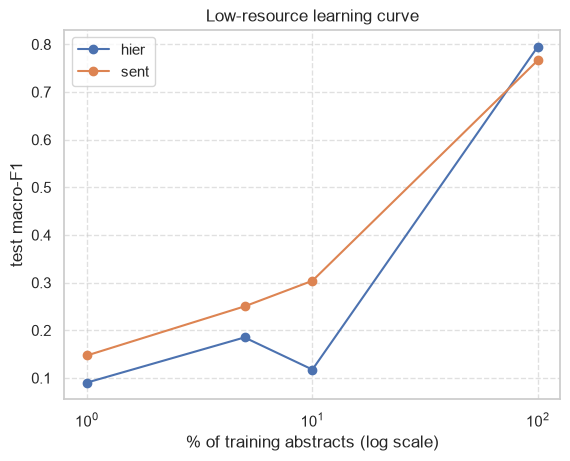

In [17]:
LR_ENCODER = 'BioBERT'
FRACS = [0.01, 0.05, 0.10]
EPOCHS_FOR_FRAC = {0.01: 10, 0.05: 6, 0.10: 4}        # fewer samples need more epochs to take the same number of steps
for frac in FRACS:
    ep = 1 if SMOKE else EPOCHS_FOR_FRAC[frac]
    for s in CFG['seeds']:
        sub = get_low_resource_subset(RUN_TRAIN, frac)      # same nested subset for every seed (see the function docstring)
        train_sentence_model(LR_ENCODER, s, sub, RUN_DEV, RUN_TEST, ep, EXTRA_EVAL, tag='sent', frac=frac)
        train_hier(LR_ENCODER, s, sub, RUN_DEV, RUN_TEST, ep, window=None, extra_eval=EXTRA_EVAL, frac=frac)

# instruction 3: low-resource learning curves — mean ± std over seeds per fraction (frac=1.0 comes from the main runs)
lr = pd.DataFrame(RESULTS)
lr = lr[(lr['key'] == LR_ENCODER) & ((lr['kind'] == 'sent') | ((lr['kind'] == 'hier') & (lr['window'] == 'full')))]
if len(lr):
    display(lr.groupby(['kind', 'frac'])['test_f1'].agg(['mean', 'std', 'count']).round(4).rename(columns={'mean': 'mean test macro-F1', 'std': 'std', 'count': 'n_seeds'}))
    for kind, grp in lr.groupby('kind'):
        m = grp.groupby('frac')['test_f1'].mean().sort_index()
        plt.plot(m.index * 100, m.values, marker='o', label=kind)
    plt.xscale('log'); plt.xlabel('% of training abstracts (log scale)'); plt.ylabel('test macro-F1')
    plt.title('Low-resource learning curve'); plt.legend(); plt.grid(True, ls='--', alpha=.6); plt.show()

# Results table

In [18]:
res = pd.DataFrame(RESULTS)
cols = [c for c in ['dev_f1', 'test_f1', 'csabstruct_f1', 'gold_f1', 'train_s', 'params_M', 'latency_ms_per_abstract'] if c in res.columns]
summary = res.groupby(['model', 'window', 'frac'], dropna=False)[cols].agg(['mean', 'std']).round(4)
summary['n_seeds'] = res.groupby(['model', 'window', 'frac'], dropna=False).size()
summary.to_csv(f'{RES_DIR}/summary.csv'); display(summary)

# review A: mean ± std macro-F1 over seeds for the two main models — does the gain survive re-initialisation?
main = res[(res['key'] == 'BioBERT') & ((res['kind'] == 'sent') | ((res['kind'] == 'hier') & (res['window'] == 'full')))]
if len(main):
    t = main.groupby('kind')['test_f1'].agg(n_seeds='count', mean='mean', std='std').round(4)
    t['mean ± std'] = t['mean'].astype(str) + ' ± ' + t['std'].astype(str)
    display(t[['n_seeds', 'mean ± std']].rename(index={'sent': 'BioBERT sentence-level', 'hier': 'BioBERT hierarchical'}))

C:\Users\pc\AppData\Local\Temp\ipykernel_24720\3287209742.py:4: Pandas4Warning: Setting a new column on a DataFrame with a MultiIndex using a key that is not a full-length tuple is deprecated and will raise in a future version. Use a full-length tuple key instead.
  summary['n_seeds'] = res.groupby(['model', 'window', 'frac'], dropna=False).size()


dev_f1     test_f1       train_s      \
                                      mean std    mean std      mean std   
model                  window frac                                         
BERT (hierarchical)    full   1.00  0.7873 NaN  0.7534 NaN  477.8171 NaN   
BERT (sentence)        NaN    1.00  0.7359 NaN  0.7038 NaN  418.7906 NaN   
BiLSTM                 NaN    1.00  0.2662 NaN  0.2696 NaN    4.9388 NaN   
BioBERT (hierarchical) full   0.01  0.1028 NaN  0.0904 NaN   37.4280 NaN   
                              0.05  0.1909 NaN  0.1851 NaN   50.1257 NaN   
                              0.10  0.1226 NaN  0.1177 NaN   79.8999 NaN   
                              1.00  0.8462 NaN  0.7953 NaN  451.3146 NaN   
                       w0     1.00  0.8176 NaN  0.7514 NaN  434.6161 NaN   
                       w1     1.00  0.8420 NaN  0.7655 NaN  453.1836 NaN   
                       w2     1.00  0.8413 NaN  0.7720 NaN  440.8782 NaN   
                       w3     1.00  0.8584 NaN  0.7850 NaN  454.9786 NaN   
BioBERT (sentence)     NaN    0.01  0.1222 NaN  0.1473 NaN   36.6505 NaN   
                              0.05  0.2616 NaN  0.2502 NaN   50.0210 NaN   
                              0.10  0.2970 NaN  0.3039 NaN   80.1494 NaN   
                              1.00  0.7941 NaN  0.7666 NaN  455.7781 NaN   
Position-only                 1.00  0.6275 NaN  0.6258 NaN    3.0803 NaN   
TF-IDF + LR                   1.00  0.7671 NaN  0.7599 NaN   57.1977 NaN   

                                    params_M     latency_ms_per_abstract      \
                                        mean std                    mean std   
model                  window frac                                             
BERT (hierarchical)    full   1.00  111.5861 NaN                506.4165 NaN   
BERT (sentence)        NaN    1.00  109.4861 NaN                499.9073 NaN   
BiLSTM                 NaN    1.00    0.7244 NaN                  2.4438 NaN   
BioBERT (hierarchical) full   0.01  110.4141 NaN                505.9626 NaN   
                              0.05  110.4141 NaN                498.5337 NaN   
                              0.10  110.4141 NaN                505.4140 NaN   
                              1.00  110.4141 NaN                503.6353 NaN   
                       w0     1.00  110.4141 NaN                477.6811 NaN   
                       w1     1.00  110.4141 NaN                514.6800 NaN   
                       w2     1.00  110.4141 NaN                505.5811 NaN   
                       w3     1.00  110.4141 NaN                503.7717 NaN   
BioBERT (sentence)     NaN    0.01  108.3141 NaN                502.8943 NaN   
                              0.05  108.3141 NaN                506.1797 NaN   
                              0.10  108.3141 NaN                496.9107 NaN   
                              1.00  108.3141 NaN                513.6344 NaN   
Position-only                 1.00       NaN NaN                     NaN NaN   
TF-IDF + LR                   1.00       NaN NaN                     NaN NaN   

                                   n_seeds  
                                            
model                  window frac          
BERT (hierarchical)    full   1.00       1  
BERT (sentence)        NaN    1.00       1  
BiLSTM                 NaN    1.00       1  
BioBERT (hierarchical) full   0.01       1  
                              0.05       1  
                              0.10       1  
                              1.00       1  
                       w0     1.00       1  
                       w1     1.00       1  
                       w2     1.00       1  
                       w3     1.00       1  
BioBERT (sentence)     NaN    0.01       1  
                              0.05       1  
                              0.10       1  
                              1.00       1  
Position-only                 1.00       1  
TF-IDF + LR                   1.00       1

,n_seeds,mean ± std
kind,,
BioBERT hierarchical,4,0.2971 ± 0.3345
BioBERT sentence-level,4,0.367 ± 0.2742


# Analysis tools
All of them read the predictions saved on disk, so they work after a restart. `run_id` examples: `tfidf`, `bilstm_s1`, `BioBERT_sent_f1.0_s1`, `BioBERT_hier-full_f1.0_s1`.

**Fair comparisons.** Runs can cover different test subsets (e.g. a smoke run vs the full test set). Never compare raw tables then — restrict every run to the abstracts *all* of them predicted on: `common_abstracts([rid1, rid2, ...])`, `per_label_f1(rid, abstracts=...)`, `accuracy_by_position(..., fair=True)`. `paired_bootstrap` realigns automatically and reports how many sentences it kept. These numbers are only interpretable after the full run (SMOKE=False, 3 seeds); on a 60-abstract smoke test set a ±0.01 macro-F1 difference is noise.

In [19]:
# [pure]
def _restrict(p, abstracts):
    # abstracts = optional set of abstract_ids; used to compare runs that were evaluated on different test subsets
    return p if abstracts is None else p[p['abstract_id'].isin(abstracts)].reset_index(drop=True)

def common_abstracts(run_ids, split='test'):
    sets = [set(load_predictions(r, split)['abstract_id']) for r in run_ids]
    return set.intersection(*sets)

def per_label_f1(run_id, split='test', abstracts=None, labels=None):
    # abstracts = restrict the evaluation to a subset of abstract_ids (e.g. common_abstracts([...])) so runs on
    # different test subsets are compared on the SAME sentences. labels = report only these classes
    # (e.g. the four CSAbstruct-compatible classes; missing classes would otherwise show a misleading 0.0).
    labs = labels or LABELS
    p = _restrict(load_predictions(run_id, split), abstracts)
    return pd.Series(f1_score(p['label'], p['pred'], labels=labs, average=None, zero_division=0), index=labs, name=run_id).round(4)

def split_consistency(run_ids, split='test'):
    # instruction 2: confirm every run was evaluated on the SAME split rows (same abstracts, same order, same gold labels)
    ref = load_predictions(run_ids[0], split); ok = True
    for rid in run_ids[1:]:
        p = load_predictions(rid, split)
        same = len(p) == len(ref) and (p['abstract_id'].values == ref['abstract_id'].values).all() \
            and (p['sent_idx'].values == ref['sent_idx'].values).all() and (p['label'].values == ref['label'].values).all()
        print(f'{rid}: {"identical split" if same else "DIFFERENT SPLIT"}'); ok = bool(ok and same)
    return ok

def accuracy_by_position(run_ids, split='test', bins=10, plot=True, fair=True):
    # fair=True: every run is evaluated on the SAME abstracts (the intersection), so the deciles are comparable
    abstracts = common_abstracts(run_ids, split) if fair else None
    out = {}
    for rid in run_ids:
        p = _restrict(load_predictions(rid, split), abstracts); rel = (p['sent_idx'] + 0.5) / p['n_sents']
        b = pd.cut(rel, bins=np.linspace(0, 1, bins + 1), labels=[f'{int(i*100/bins)}-{int((i+1)*100/bins)}%' for i in range(bins)])
        out[rid] = (p['label'] == p['pred']).groupby(b, observed=False).mean() * 100
    out = pd.DataFrame(out)
    if plot:
        out.plot(marker='o', figsize=(10, 5)); plt.ylabel('accuracy (%)'); plt.xlabel('relative position in abstract'); plt.title('Accuracy by sentence position'); plt.grid(True, ls='--', alpha=.6); plt.show()
    return out.round(1)

def _cm_per_abstract(p):
    y = p['label'].map(L2I).values; q = p['pred'].map(L2I).values
    gid = pd.factorize(p['abstract_id'])[0]; cm = np.zeros((gid.max() + 1, NC, NC), dtype=np.int64)
    np.add.at(cm, (gid, y, q), 1); return cm

def _macro_f1_cm(cm):
    tp = np.diag(cm).astype(float); prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(cm.sum(1), 1)
    return float(np.mean(2 * prec * rec / np.maximum(prec + rec, 1e-12)))

def paired_bootstrap(run_a, run_b, split='test', n_boot=2000, seed=1):
    # Statistical design (review B): resample complete ABSTRACTS with replacement (sentences within one abstract
    # are correlated — resampling individual sentences independently would be invalid). For every bootstrap
    # sample both models are scored on the SAME resampled abstracts: their confusion matrices are summed, macro-F1
    # is computed SEPARATELY for each model, and the PAIRED difference F1_a - F1_b is recorded. Reported: the mean
    # paired difference, its 95% percentile CI, and a two-sided p-value (share of samples where the sign flips).
    pa, pb = load_predictions(run_a, split), load_predictions(run_b, split)
    aligned = len(pa) == len(pb) and (pa['abstract_id'].values == pb['abstract_id'].values).all() and (pa['sent_idx'].values == pb['sent_idx'].values).all()
    if not aligned:      # the runs covered different test subsets: keep only sentences BOTH of them predicted on
        m = pa.merge(pb, on=['abstract_id', 'sent_idx'], suffixes=('_a', '_b'))
        print(f'paired_bootstrap: runs differ, restricted to {len(m)} common sentences / {m["abstract_id"].nunique()} abstracts')
        pa = m.rename(columns={'n_sents_a': 'n_sents', 'label_a': 'label', 'pred_a': 'pred'})
        pb = m.rename(columns={'n_sents_b': 'n_sents', 'label_b': 'label', 'pred_b': 'pred'})
    ca, cb = _cm_per_abstract(pa), _cm_per_abstract(pb); n = len(ca); rng = np.random.default_rng(seed)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, n, n); diffs[i] = _macro_f1_cm(ca[idx].sum(0)) - _macro_f1_cm(cb[idx].sum(0))
    p = min(1.0, 2 * min((diffs <= 0).mean(), (diffs >= 0).mean()))
    res = dict(F1_a=round(_macro_f1_cm(ca.sum(0)), 4), F1_b=round(_macro_f1_cm(cb.sum(0)), 4),
               diff_mean=round(diffs.mean(), 4), ci95=(round(np.percentile(diffs, 2.5), 4), round(np.percentile(diffs, 97.5), 4)), p_two_sided=round(p, 4))
    print(f'{run_a} vs {run_b}:', res); return res

def error_sample(run_id, df, split='test', n=50, seed=1):
    # df = the dataframe that was evaluated (RUN_TEST, EXTRA_EVAL[...]); writes a CSV to categorise the errors by hand
    p = load_predictions(run_id, split); d = df.reset_index(drop=True).copy(); d['pred'] = p['pred'].values
    d['prev'] = d['text'].shift(1).where(d['sent_idx'] > 0, ''); d['next'] = d['text'].shift(-1).where(d['sent_idx'] < d['n_sents'] - 1, '')
    wrong = d[d['label'] != d['pred']].sample(n=min(n, (d['label'] != d['pred']).sum()), random_state=seed)
    wrong[['abstract_id', 'sent_idx', 'n_sents', 'label', 'pred', 'prev', 'text', 'next']].assign(cause='').to_csv(f'{RES_DIR}/errors_{run_id}.csv', index=False)
    return wrong[['label', 'pred', 'text']]

def confusion_focus(run_id, df, label='OBJECTIVE', top=10):
    # review C: where does one true label go? -> predicted-class counts + example sentences.
    # df = the dataframe that was evaluated (e.g. RUN_TEST), so predictions line up with its rows.
    p = load_predictions(run_id, 'test'); d = df.reset_index(drop=True).copy(); d['pred'] = p['pred'].values
    sub = d[d['label'] == label]
    counts = sub['pred'].value_counts().rename_axis('pred').to_frame('n')
    counts['share_%'] = (100 * counts['n'] / max(len(sub), 1)).round(1)
    print(f'{run_id}: true {label} -> predicted as ({len(sub)} test sentences):'); display(counts)
    wrong = sub[sub['pred'] != label]
    wrong = wrong.assign(prev=d['text'].shift(1).where(d['sent_idx'] > 0, '').loc[wrong.index],
                         next=d['text'].shift(-1).where(d['sent_idx'] < d['n_sents'] - 1, '').loc[wrong.index])
    return wrong[['abstract_id', 'sent_idx', 'label', 'pred', 'prev', 'text', 'next']].head(top)

def objective_audit(run_id, df, label='OBJECTIVE', n=50):
    # instruction 1: manual audit of one label's errors. Writes errors_<run_id>_<label>_audit.csv with context and
    # two diagnostic columns: label_share = share of the abstract's sentences carrying THIS gold label (a low share
    # suggests the sentence does not match its section header), maj_label = the abstract's majority gold label.
    # Fill 'cause' with one of: ambiguous | inherited-section-label | model-limitation; optionally put the
    # corrected gold label in 'gold_fixed' when the annotation itself is wrong (used by audit_impact).
    p = load_predictions(run_id, 'test'); d = df.reset_index(drop=True).copy(); d['pred'] = p['pred'].values
    wrong = d[(d['label'] == label) & (d['pred'] != label)].copy()
    share = d.groupby(['abstract_id', 'label']).size().rename('n').reset_index()
    share['label_share'] = (share['n'] / share.groupby('abstract_id')['n'].transform('sum')).round(3)
    maj = d.groupby('abstract_id')['label'].agg(lambda s: s.value_counts().index[0]).rename('maj_label').reset_index()
    wrong = wrong.merge(share[['abstract_id', 'label', 'label_share']], on=['abstract_id', 'label']).merge(maj, on='abstract_id')
    wrong['prev'] = d['text'].shift(1).where(d['sent_idx'] > 0, '').loc[wrong.index]
    wrong['next'] = d['text'].shift(-1).where(d['sent_idx'] < d['n_sents'] - 1, '').loc[wrong.index]
    cols = ['abstract_id', 'sent_idx', 'n_sents', 'label', 'pred', 'maj_label', 'label_share', 'prev', 'text', 'next', 'cause', 'gold_fixed']
    sheet = (wrong.sample(n=min(n, len(wrong)), random_state=1) if len(wrong) > n else wrong).assign(cause='', gold_fixed='')[cols].sort_values(['abstract_id', 'sent_idx'])
    sheet.to_csv(f'{RES_DIR}/errors_{run_id}_{label}_audit.csv', index=False)
    print(f'wrote {len(sheet)} {label} errors -> {RES_DIR}/errors_{run_id}_{label}_audit.csv — fill the cause column')
    return sheet

def bg_obj_by_position(run_ids, split='test', bins=10):
    # instruction 4: BACKGROUND vs OBJECTIVE accuracy by position decile (especially the abstract start),
    # evaluated on the COMMON abstracts of all runs so the deciles are comparable. Small n per decile = noise.
    abstracts = common_abstracts(run_ids, split)
    labels = [f'{int(i*100/bins)}-{int((i+1)*100/bins)}%' for i in range(bins)]
    out = {}
    for rid in run_ids:
        p = _restrict(load_predictions(rid, split), abstracts)
        b = pd.cut((p['sent_idx'] + 0.5) / p['n_sents'], bins=np.linspace(0, 1, bins + 1), labels=labels)
        cols = {}
        for lab in ['BACKGROUND', 'OBJECTIVE']:
            m = (p['label'] == lab).values
            cols[f'{lab} n'] = pd.Series(m, index=b.values).groupby(level=0, observed=False).sum().reindex(labels).astype(int)
            cols[f'{lab} acc'] = (pd.Series((p['pred'].values == lab)[m], index=b[m].values).groupby(level=0, observed=False).mean() * 100).reindex(labels).round(1)
        out[rid] = pd.DataFrame(cols)
    return out

def audit_impact(run_id, df, label='OBJECTIVE'):
    # instruction 4: after the audit sheet is filled, separate annotation noise from genuine model errors.
    # Reports the cause distribution and the corrected macro-F1 when 'gold_fixed' corrections were supplied.
    path = f'{RES_DIR}/errors_{run_id}_{label}_audit.csv'
    if not os.path.exists(path): print('audit sheet missing:', path); return None
    a = pd.read_csv(path)
    if a['cause'].fillna('').str.strip().eq('').all(): print('fill the cause column in', path, 'first'); return a
    print(f'{run_id}: {label} audit causes:'); display(a['cause'].fillna('(blank)').value_counts().to_frame('n'))
    if 'gold_fixed' not in a or a['gold_fixed'].fillna('').astype(str).str.strip().eq('').all():
        print('no gold_fixed corrections yet: corrected F1 cannot be computed'); return a
    p = load_predictions(run_id, 'test'); y, q = p['label'].values.copy(), p['pred'].values
    base = f1_score(y, q, labels=LABELS, average='macro', zero_division=0)
    for _, r in a[a['gold_fixed'].fillna('').astype(str).str.strip().ne('')].iterrows():
        y[(p['abstract_id'] == r['abstract_id']).values & (p['sent_idx'] == r['sent_idx']).values] = r['gold_fixed']
    corr = f1_score(y, q, labels=LABELS, average='macro', zero_division=0)
    print(f'test macro-F1 {base:.4f} -> corrected {corr:.4f} (+{corr - base:.4f}). Only the audited sample was corrected, so this UNDERESTIMATES the annotation-noise effect on the full set.')
    return a

fair comparison on 60 common test abstracts


,tfidf,BioBERT_sent_f1.0_s1,BioBERT_hier-full_f1.0_s1,hier_minus_sentence
BACKGROUND,0.7182,0.6548,0.7456,0.0908
OBJECTIVE,0.6000,0.6078,0.6170,0.0092
METHODS,0.8661,0.8795,0.8811,0.0016
RESULTS,0.8676,0.8798,0.8755,-0.0043
CONCLUSIONS,0.7593,0.8113,0.8571,0.0458


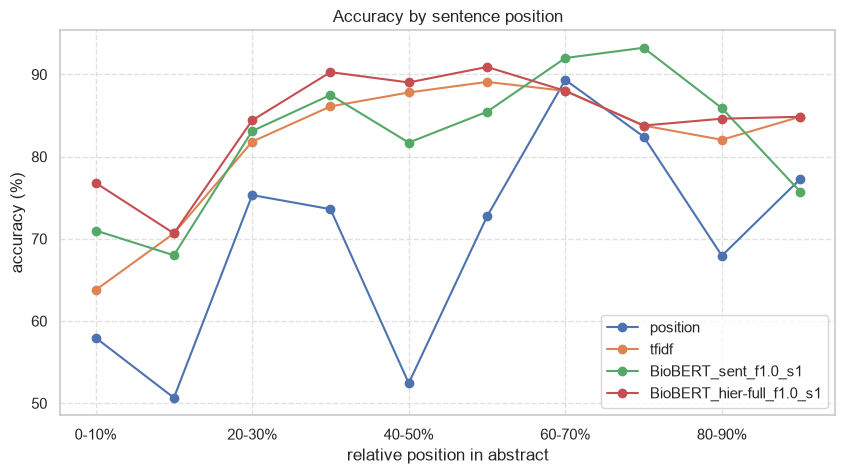

,position,tfidf,BioBERT_sent_f1.0_s1,BioBERT_hier-full_f1.0_s1
0-10%,58.0,63.8,71.0,76.8
10-20%,50.7,70.7,68.0,70.7
20-30%,75.3,81.8,83.1,84.4
30-40%,73.6,86.1,87.5,90.3
40-50%,52.4,87.8,81.7,89.0
50-60%,72.7,89.1,85.5,90.9
60-70%,89.3,88.0,92.0,88.0
70-80%,82.4,83.8,93.2,83.8
80-90%,67.9,82.1,85.9,84.6
90-100%,77.3,84.8,75.8,84.8


BioBERT_hier-full_f1.0_s1 vs BioBERT_sent_f1.0_s1: {'F1_a': 0.7953, 'F1_b': 0.7666, 'diff_mean': np.float64(0.0289), 'ci95': (np.float64(0.003), np.float64(0.0552)), 'p_two_sided': np.float64(0.028)}
=== BioBERT_sent_f1.0_s1: macro-F1 = 0.7666
             Precision  Recall      F1  Support
BACKGROUND      0.7237  0.5978  0.6548       92
OBJECTIVE       0.5439  0.6889  0.6078       45
METHODS         0.8312  0.9336  0.8795      211
RESULTS         0.9303  0.8346  0.8798      272
CONCLUSIONS     0.7890  0.8350  0.8113      103


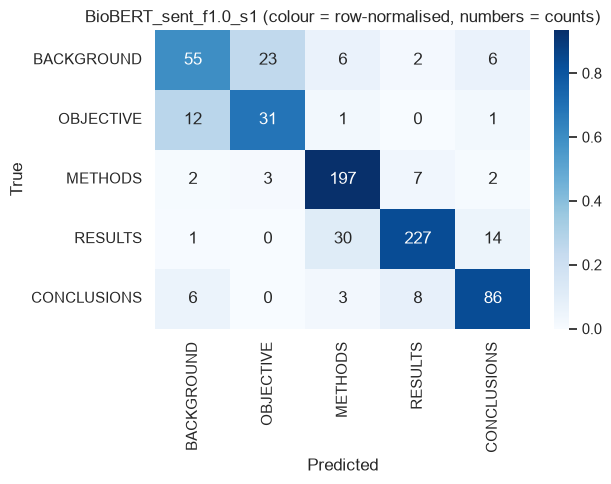

=== BioBERT_hier-full_f1.0_s1: macro-F1 = 0.7953
             Precision  Recall      F1  Support
BACKGROUND      0.8182  0.6848  0.7456       92
OBJECTIVE       0.5918  0.6444  0.6170       45
METHODS         0.8230  0.9479  0.8811      211
RESULTS         0.9646  0.8015  0.8755      272
CONCLUSIONS     0.7734  0.9612  0.8571      103


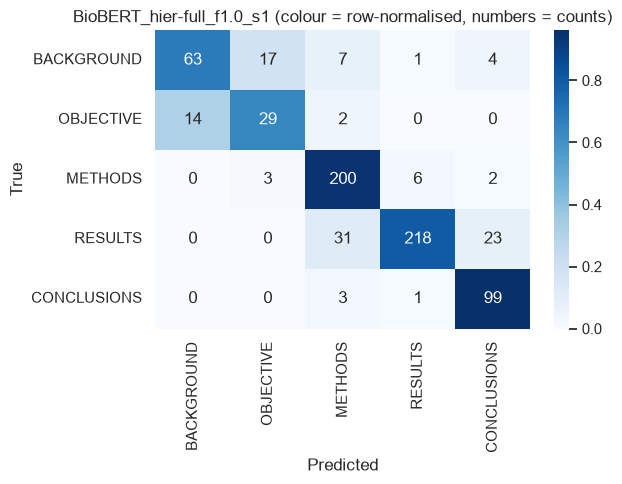

BioBERT_hier-full_f1.0_s1: true OBJECTIVE -> predicted as (45 test sentences):


,n,share_%
pred,,
OBJECTIVE,29,64.4
BACKGROUND,14,31.1
METHODS,2,4.4


,abstract_id,sent_idx,label,pred,prev,text,next
44,25829103,0,OBJECTIVE,BACKGROUND,,Depressive disorders are one of the leading co...,Numerous studies have demonstrated that pharma...
45,25829103,1,OBJECTIVE,BACKGROUND,Depressive disorders are one of the leading co...,Numerous studies have demonstrated that pharma...,Psycho-education as an intervention has been s...
46,25829103,2,OBJECTIVE,BACKGROUND,Numerous studies have demonstrated that pharma...,Psycho-education as an intervention has been s...,The present study aimed to assess the impact o...
190,25265132,1,OBJECTIVE,METHODS,The effects of combined oxycodone/naloxone pro...,All patients had opioid-induced constipation (...,This pooled analysis included @ patients with ...
278,25175385,0,OBJECTIVE,BACKGROUND,,Patients with type @ diabetes are generally tr...,The aim of this study is to evaluate the effec...
372,24893684,0,OBJECTIVE,BACKGROUND,,There have been several studies of atrial fibr...,The aim of the study was therefore to describe...
386,24638003,0,OBJECTIVE,BACKGROUND,,The ACOSOG ( American College of Surgeons Onco...,We sought to determine the pathologic and mole...
431,24337434,0,OBJECTIVE,BACKGROUND,,Larger biopsy specimens or increasing the numb...,The aims of this study was to compare the diag...
432,24337434,1,OBJECTIVE,BACKGROUND,Larger biopsy specimens or increasing the numb...,The aims of this study was to compare the diag...,The concordance rate between EFB and ESD speci...
440,25378648,0,OBJECTIVE,BACKGROUND,,Prospective trials specifically designed for e...,This trial was designed to clarify whether the...


BioBERT_sent_f1.0_s1: true OBJECTIVE -> predicted as (45 test sentences):


,n,share_%
pred,,
OBJECTIVE,31,68.9
BACKGROUND,12,26.7
METHODS,1,2.2
CONCLUSIONS,1,2.2


,abstract_id,sent_idx,label,pred,prev,text,next
44,25829103,0,OBJECTIVE,BACKGROUND,,Depressive disorders are one of the leading co...,Numerous studies have demonstrated that pharma...
45,25829103,1,OBJECTIVE,BACKGROUND,Depressive disorders are one of the leading co...,Numerous studies have demonstrated that pharma...,Psycho-education as an intervention has been s...
46,25829103,2,OBJECTIVE,BACKGROUND,Numerous studies have demonstrated that pharma...,Psycho-education as an intervention has been s...,The present study aimed to assess the impact o...
190,25265132,1,OBJECTIVE,METHODS,The effects of combined oxycodone/naloxone pro...,All patients had opioid-induced constipation (...,This pooled analysis included @ patients with ...
278,25175385,0,OBJECTIVE,BACKGROUND,,Patients with type @ diabetes are generally tr...,The aim of this study is to evaluate the effec...
372,24893684,0,OBJECTIVE,BACKGROUND,,There have been several studies of atrial fibr...,The aim of the study was therefore to describe...
386,24638003,0,OBJECTIVE,BACKGROUND,,The ACOSOG ( American College of Surgeons Onco...,We sought to determine the pathologic and mole...
431,24337434,0,OBJECTIVE,BACKGROUND,,Larger biopsy specimens or increasing the numb...,The aims of this study was to compare the diag...
440,25378648,0,OBJECTIVE,BACKGROUND,,Prospective trials specifically designed for e...,This trial was designed to clarify whether the...
441,25378648,1,OBJECTIVE,BACKGROUND,Prospective trials specifically designed for e...,This trial was designed to clarify whether the...,"Elderly patients ( age @ years , ECOG performa..."


wrote 16 OBJECTIVE errors -> ./medstruct/results/errors_BioBERT_hier-full_f1.0_s1_OBJECTIVE_audit.csv — fill the cause column
fill the cause column in ./medstruct/results/errors_BioBERT_hier-full_f1.0_s1_OBJECTIVE_audit.csv first
BioBERT_sent_f1.0_s1: DIFFERENT SPLIT
BioBERT_hier-full_f1.0_s1: DIFFERENT SPLIT
--- BioBERT_sent_f1.0_s1 ---


C:\Users\pc\AppData\Local\Temp\ipykernel_24720\963893726.py:136: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  if a['cause'].fillna('').str.strip().eq('').all(): print('fill the cause column in', path, 'first'); return a


,BACKGROUND n,BACKGROUND acc,OBJECTIVE n,OBJECTIVE acc
0-10%,39,79.5,27,59.3
10-20%,27,40.7,14,78.6
20-30%,8,37.5,4,100.0
30-40%,1,0.0,0,NaN
40-50%,1,0.0,0,NaN
50-60%,0,NaN,0,NaN
60-70%,0,NaN,0,NaN
70-80%,2,50.0,0,NaN
80-90%,2,50.0,0,NaN
90-100%,12,66.7,0,NaN


--- BioBERT_hier-full_f1.0_s1 ---


,BACKGROUND n,BACKGROUND acc,OBJECTIVE n,OBJECTIVE acc
0-10%,39,89.7,27,59.3
10-20%,27,51.9,14,71.4
20-30%,8,62.5,4,75.0
30-40%,1,100.0,0,NaN
40-50%,1,0.0,0,NaN
50-60%,0,NaN,0,NaN
60-70%,0,NaN,0,NaN
70-80%,2,0.0,0,NaN
80-90%,2,50.0,0,NaN
90-100%,12,58.3,0,NaN


In [20]:
# Example analysis (uses the first seed of each model; adapt the run ids once the real runs are done)
s0 = CFG['seeds'][0]
ids = dict(sentence=f'BioBERT_sent_f1.0_s{s0}', hier=f'BioBERT_hier-full_f1.0_s{s0}')
if all(os.path.exists(f'{PRED_DIR}/{r}__test.csv') for r in ids.values()):
    # FAIR COMPARISON: restrict every run to the abstracts ALL of them predicted on
    common = common_abstracts(['tfidf', ids['sentence'], ids['hier']])
    print(f'fair comparison on {len(common)} common test abstracts')
    display(pd.concat([per_label_f1(r, abstracts=common) for r in ['tfidf', ids['sentence'], ids['hier']]], axis=1).assign(hier_minus_sentence=lambda d: (d[ids['hier']] - d[ids['sentence']]).round(4)))
    display(accuracy_by_position(['position', 'tfidf', ids['sentence'], ids['hier']], fair=True))
    paired_bootstrap(ids['hier'], ids['sentence'])
    for rid in ids.values(): p = _restrict(load_predictions(rid, 'test'), common); evaluate_model(p['label'], p['pred'], name=rid)
    display(confusion_focus(ids['hier'], RUN_TEST, 'OBJECTIVE'))      # review C: OBJECTIVE vs BACKGROUND/METHODS
    display(confusion_focus(ids['sentence'], RUN_TEST, 'OBJECTIVE'))
    objective_audit(ids['hier'], RUN_TEST, 'OBJECTIVE')      # instruction 1 (prev. round): manual audit sheet — fill 'cause' and optional 'gold_fixed'
    audit_impact(ids['hier'], RUN_TEST, 'OBJECTIVE')         # instruction 4: annotation noise vs genuine model errors (after the sheet is filled)
    split_consistency(['tfidf', ids['sentence'], ids['hier']])      # instruction 2: all runs evaluated on the same split
    for rid, t in bg_obj_by_position([ids['sentence'], ids['hier']]).items():      # instruction 4 (prev. round): BACKGROUND vs OBJECTIVE at the abstract start
        print(f'--- {rid} ---'); display(t)
    CSA_OK = ['BACKGROUND', 'OBJECTIVE', 'METHODS', 'RESULTS']      # instruction 6: the four CSAbstruct-compatible classes
    for split in ['csabstruct', 'gold']:      # instruction 5: unstructured / out-of-domain sets
        rids = [r for r in ['tfidf', ids['sentence'], ids['hier']] if os.path.exists(f'{PRED_DIR}/{r}__{split}.csv')]
        if not rids: continue
        p0 = load_predictions(rids[0], split)
        labs = [l for l in LABELS if (p0['label'] == l).any()]      # shared-label rule (same as score_extra)
        display(pd.concat([per_label_f1(r, split=split, labels=labs) for r in rids], axis=1))
        if split == 'csabstruct':      # no CONCLUSIONS class exists there: show what the models predict instead
            display(load_predictions(rids[-1], split)['pred'].value_counts().rename_axis('pred').to_frame('n').rename(columns={'n': 'pred count'}))
else:
    print('Run the experiments first, then adjust the run ids above.')

# Annotation tools (gold set of unstructured abstracts)
1. Put the raw abstracts (one per line, or a list) through `make_annotation_sheet`. It splits sentences and writes a CSV with an empty `label` column.
2. Fill the labels (BACKGROUND / OBJECTIVE / METHODS / RESULTS / CONCLUSIONS) in a spreadsheet. Save pass 1 as `gold_pass1.csv`.
3. **At least two weeks later**, make a fresh copy of the sheet without your old labels, annotate again, and save it as `gold_pass2.csv`.
4. `annotation_kappa` computes Cohen's kappa and lists disagreements. Resolve them into `gold_pass_final.csv` (the file the evaluation code reads).

In [21]:
# [pure]
def split_sentences(text):
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+(?=[A-Z(])', text.strip()) if s.strip()]

def make_annotation_sheet(abstracts, path):
    rows = [(f'g{i+1}', j, s, '') for i, a in enumerate(abstracts) for j, s in enumerate(split_sentences(a))]
    pd.DataFrame(rows, columns=['abstract_id', 'sent_idx', 'text', 'label']).to_csv(path, index=False); print(len(rows), 'sentences ->', path)

def annotation_kappa(path1, path2):
    a, b = pd.read_csv(path1, dtype={'abstract_id': str}), pd.read_csv(path2, dtype={'abstract_id': str})
    assert (a['text'].values == b['text'].values).all(), 'the two sheets must contain the same sentences in the same order'
    la, lb = a['label'].str.upper().str.strip(), b['label'].str.upper().str.strip()
    kappa = cohen_kappa_score(la, lb, labels=LABELS)
    print(f"Cohen's kappa = {kappa:.3f}, raw agreement = {(la == lb).mean():.3f}")
    print(pd.crosstab(la, lb, rownames=['pass 1'], colnames=['pass 2']).reindex(index=LABELS, columns=LABELS, fill_value=0))
    dis = a.assign(pass1=la, pass2=lb)[la != lb][['abstract_id', 'sent_idx', 'text', 'pass1', 'pass2']]
    return kappa, dis

# Abstract Analyzer (demo application)
The central feature of the MedStruct app. Workflow: **paste a biomedical abstract** → the text is split into sentences → BioBERT classifies every sentence → each sentence is shown with its **predicted rhetorical role**, a **confidence score** and the **full probability distribution over the five classes** → the **structured abstract is reconstructed** by grouping the sentences under their predicted role → predictions can be **exported as CSV or JSON**.

- Requires a trained checkpoint: the BioBERT hierarchical / sentence model from a real run (`SMOKE = False`), or the BiLSTM checkpoint (saved in every mode, lower quality).
- Numbers are normalised to `@` before classification, exactly as in the training data.
- The illustrative example in the task description is **not** a real model output; run the analyzer to get actual predictions.


In [22]:
# [pure]
# Abstract Analyzer (the application's main feature):
# paste a biomedical abstract -> sentence split -> BioBERT classifies each sentence -> role + confidence +
# full probability distribution -> reconstructed structured abstract -> export CSV/JSON.
# Needs a trained checkpoint: BioBERT hier/sent (real runs) or BiLSTM (saved in every mode).

_ANALYZER = {}      # caches the loaded demo model between calls

def pick_analyzer_run():
    # best available checkpoint for the demo: BioBERT hierarchical > BioBERT sentence > other > BiLSTM
    pref = {'hier': 0, 'sent': 1, 'bilstm': 2}
    avail = [(r['run_id'], r['kind'], r['dev_f1']) for r in RESULTS if os.path.exists(f'{CKPT_DIR}/{r["run_id"]}.pt')]
    if not avail: return None
    return sorted(avail, key=lambda t: (pref[t[1]], 0 if 'BioBERT' in t[0] else 1, -t[2]))[0][0]

def load_demo_model(run_id):
    # returns (kind, probs_fn); probs_fn(df) -> (N, NC) class probabilities in df row order
    rec = next(r for r in RESULTS if r['run_id'] == run_id); kind = rec['kind']
    ck = torch.load(f'{CKPT_DIR}/{run_id}.pt', map_location='cpu')
    if kind == 'bilstm':
        w2i = ck['w2i']; model = BiLSTMClassifier(len(w2i)); model.load_state_dict(ck['state']); model.to(DEVICE).eval()
        def probs_fn(df):
            X = encode_texts(df['text'].tolist(), w2i); out = []
            with torch.no_grad():
                for i in range(0, len(X), 256): out.append(F.softmax(model(X[i:i+256].to(DEVICE)), -1).cpu())
            return torch.cat(out).numpy()
    elif kind == 'sent':
        name = MODEL_NAMES[rec['key']]; tok = make_tokenizer(name)
        model = SentClassifier(make_encoder(name)); model.load_state_dict(ck); model.to(DEVICE).eval()
        def probs_fn(df):
            ids, mask = tokenize(tok, df['text']); out = []
            with torch.no_grad():
                for i in range(0, len(ids), 256):
                    with torch.amp.autocast('cuda', enabled=AMP): lg = model(ids[i:i+256].to(DEVICE), mask[i:i+256].to(DEVICE))
                    out.append(torch.softmax(lg.float(), -1).cpu())
            return torch.cat(out).numpy()
    else:
        name = MODEL_NAMES[rec['key']]; tok = make_tokenizer(name)
        wtag = str(rec['window']); model = HierModel(make_encoder(name), window=None if wtag == 'full' else int(wtag[1:]))
        model.load_state_dict(ck); model.to(DEVICE).eval()
        def probs_fn(df):
            out = []      # the fake gold 'label' column is required by AbstractDataset but never used (leakage self-check proved this)
            with torch.no_grad():
                for ids, mask, _, sm in DataLoader(AbstractDataset(df, tok), batch_size=8, shuffle=False, collate_fn=collate_abstracts):
                    smd = sm.to(DEVICE)
                    with torch.amp.autocast('cuda', enabled=AMP): lg = model(ids.to(DEVICE), mask.to(DEVICE), smd)
                    out.append(torch.softmax(lg.float(), -1)[smd].cpu())
            return torch.cat(out).numpy()
    print(f'loaded demo model: {run_id} ({kind})'); return kind, probs_fn

ABBREV = r'(?:e\.g|i\.e|et al|vs|cf|ca|no|approx|Fig|Figs|Eq|Ref|pp)'
def split_sentences(text):
    # rule-based splitter: protect common abbreviations, then split on .!? followed by a capital/number/quote.
    # (PubMed abstracts are one-sentence-per-line, so the models were never trained on splitting — keep it
    #  simple and inspect the split output when in doubt.)
    text = ' '.join(str(text).split())
    text = re.sub(rf'\b{ABBREV}\.', lambda m: m.group(0)[:-1] + '§', text)
    parts = re.split(r'(?<=[.!?])\s+(?=[A-Z0-9("\'])', text)
    return [p.replace('§', '.').strip() for p in parts if p.strip()]

def analyze_abstract(text, run_id=None, export=None):
    # text -> sentences -> predicted role + confidence + probability distribution -> structured abstract.
    # export: 'csv' | 'json' | 'both' | None (files are written to {RES_DIR}/analyzer_demo.*)
    sents = split_sentences(normalize_numbers(text))
    if not sents: print('no sentences found'); return None
    run_id = run_id or pick_analyzer_run()
    if run_id is None: raise RuntimeError('No checkpoints found yet — run the experiment cells first (BiLSTM checkpoints are saved even in SMOKE mode).')
    if _ANALYZER.get('run_id') != run_id: _ANALYZER['run_id'] = run_id; _ANALYZER['fn'] = load_demo_model(run_id)
    kind, probs_fn = _ANALYZER['fn']
    df = pd.DataFrame({'abstract_id': 'demo', 'sent_idx': range(len(sents)), 'n_sents': len(sents), 'label': LABELS[0], 'text': sents})
    probs = probs_fn(df)
    res = pd.DataFrame({'sentence': range(1, len(sents) + 1), 'text': sents,
                        'pred': [LABELS[i] for i in probs.argmax(1)], 'confidence': (probs.max(1) * 100).round(1)})
    res = pd.concat([res, pd.DataFrame((probs * 100).round(1), columns=[f'p_{l}' for l in LABELS])], axis=1)
    print(f'model: {run_id} ({kind}) — {len(sents)} sentences')
    display(res)
    print('\nStructured abstract (sentences grouped by predicted role):')
    for lab in LABELS:
        grp = res.loc[res['pred'] == lab, 'text'].tolist()
        if grp: print(f'  {lab}: ' + ' '.join(grp))
    if export:
        for fmt in (['csv', 'json'] if export == 'both' else [export]):
            path = f'{RES_DIR}/analyzer_demo.{fmt}'
            if fmt == 'json':
                recs = [dict(sentence=int(r['sentence']), text=r['text'], pred=r['pred'], confidence=float(r['confidence']),
                             probabilities={l: float(r[f'p_{l}']) for l in LABELS}) for _, r in res.iterrows()]
                json.dump(recs, open(path, 'w', encoding='utf-8'), indent=2, ensure_ascii=False)
            else:
                res.to_csv(path, index=False)
            print('exported:', path)
            try:
                from google.colab import files; files.download(path)      # auto-download on Colab, silent elsewhere
            except ImportError: pass
    return res

EXAMPLE = ('Depression is a major public health problem. This study aimed to evaluate a new intervention. '
           'We conducted a randomized controlled trial involving 250 patients. The intervention improved patient outcomes. '
           'These findings support further investigation.')      # the illustrative example, not a real model output

if pick_analyzer_run():
    analyze_abstract(EXAMPLE)
else:
    print('Abstract Analyzer is ready, but no trained checkpoints exist yet.')
    print('Run the experiment cells first (BiLSTM checkpoints are saved even in SMOKE mode; BioBERT needs SMOKE = False).')
    print('Sentence-splitting preview of the example:')
    display(pd.DataFrame({'sentence': range(1, len(split_sentences(EXAMPLE)) + 1), 'text': split_sentences(EXAMPLE)}))


loaded demo model: bilstm_s1 (bilstm)
model: bilstm_s1 (bilstm) — 5 sentences


,sentence,text,pred,confidence,p_BACKGROUND,p_OBJECTIVE,p_METHODS,p_RESULTS,p_CONCLUSIONS
0,1,Depression is a major public health problem.,BACKGROUND,29.100000,29.100000,15.800000,23.400000,8.4,23.299999
1,2,This study aimed to evaluate a new intervention.,METHODS,28.600000,23.500000,16.799999,28.600000,8.3,22.700001
2,3,We conducted a randomized controlled trial inv...,METHODS,52.400002,11.600000,6.300000,52.400002,17.5,12.200000
3,4,The intervention improved patient outcomes.,METHODS,33.900002,17.600000,10.600000,33.900002,12.8,25.100000
4,5,These findings support further investigation.,CONCLUSIONS,27.000000,24.200001,15.200000,22.500000,11.1,27.000000



Structured abstract (sentences grouped by predicted role):
  BACKGROUND: Depression is a major public health problem.
  METHODS: This study aimed to evaluate a new intervention. We conducted a randomized controlled trial involving @ patients. The intervention improved patient outcomes.
  CONCLUSIONS: These findings support further investigation.


In [23]:
# Optional interactive UI for the Abstract Analyzer (needs ipywidgets; otherwise call analyze_abstract() directly).
try:
    import ipywidgets as W
    from IPython.display import clear_output
    _ta = W.Textarea(layout=W.Layout(width='100%', height='140px'), placeholder='Paste a biomedical abstract here...')
    _btn = W.Button(description='Analyze', button_style='primary')
    _fmt = W.Dropdown(options=['none', 'csv', 'json', 'both'], value='none', description='export:')
    _out = W.Output()
    def _run(_):
        with _out: clear_output(); analyze_abstract(_ta.value, export=None if _fmt.value == 'none' else _fmt.value)
    _btn.on_click(_run)
    display(W.VBox([W.HTML('<b>Abstract Analyzer</b> — paste a biomedical abstract, then click Analyze:'), _ta, W.HBox([_btn, _fmt]), _out]))
except ImportError:
    print('ipywidgets not installed — call analyze_abstract(text, export=...) directly, or pip install ipywidgets for the UI.')


# Notes for the paper
- Report **test** macro-F1 for the final table, chosen models and epochs come from **dev** only.
- Report mean ± std over seeds from `summary.csv`; use `paired_bootstrap` for the claims about differences.
- Say in the paper which data you used for each result (20k subset or full 200k), that digits are normalised to `@`, how CSAbstruct labels were mapped, and that `OTHER` sentences are context only.
- Keep `results.csv`, `summary.csv` and the `preds/` folder in the GitHub release for replication.